In [1]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.precision', 4)

In [2]:
with zipfile.ZipFile('customers.zip') as z:
    raw = pd.read_csv(z.open('customers.csv'))

FEATURES = ['Age', 'Education', 'YearsEmployed', 'Income', 'CardDebt', 'OtherDebt', 'DebtIncomeRatio']
data = raw[FEATURES].astype(float)


def standardize(X):
    return (X - X.mean(0)) / X.std(0)

def pairwise(A, B):
    d2 = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return np.sqrt(np.maximum(d2, 0))


X = standardize(data.to_numpy(float))
D = pairwise(X, X)
print(X.shape)

(850, 7)


In [3]:
LINKAGES = {'single': 'Single linkage', 'complete': 'Complete linkage', 'average': 'Group average', 'ward': 'Ward distance'}


def lance_williams(method, d_ki, d_kj, d_ij, n_i, n_j, n_k):
    if method == 'single':
        return np.minimum(d_ki, d_kj)
    if method == 'complete':
        return np.maximum(d_ki, d_kj)
    if method == 'average':
        return (n_i * d_ki + n_j * d_kj) / (n_i + n_j)
    return ((n_i + n_k) * d_ki + (n_j + n_k) * d_kj - n_k * d_ij) / (n_i + n_j + n_k)


def agglomerative(D, method):
    n = len(D)
    D = D ** 2 if method == 'ward' else D.copy()
    np.fill_diagonal(D, np.inf)
    size = np.ones(n)
    ids = np.arange(n)
    Z = np.zeros((n - 1, 4))
    for s in range(n - 1):
        i, j = divmod(D.argmin(), n)
        h = D[i, j]
        new = lance_williams(method, D[i], D[j], h, size[i], size[j], size)
        Z[s] = [min(ids[i], ids[j]), max(ids[i], ids[j]), np.sqrt(h) if method == 'ward' else h, size[i] + size[j]]
        D[i, :] = new
        D[:, i] = new
        D[j, :] = D[:, j] = np.inf
        D[i, i] = np.inf
        size[i] += size[j]
        ids[i] = n + s
    return Z


def leaf_order(Z):
    n = len(Z) + 1
    order, stack = [], [2 * n - 2]
    while stack:
        c = stack.pop()
        if c < n:
            order.append(c)
        else:
            a, b = Z[c - n, :2].astype(int)
            stack += [b, a]
    return np.array(order)


def cut(Z, k):
    n = len(Z) + 1
    members = {i: [i] for i in range(n)}
    for s in range(n - k):
        a, b = Z[s, :2].astype(int)
        members[n + s] = members.pop(a) + members.pop(b)
    pos = np.empty(n, int)
    pos[leaf_order(Z)] = np.arange(n)
    labels = np.empty(n, int)
    for label, m in enumerate(sorted(members.values(), key=lambda m: pos[m].min())):
        labels[m] = label
    return labels


def cophenetic(Z):
    n = len(Z) + 1
    Cd = np.zeros((n, n))
    members = {i: [i] for i in range(n)}
    for s, (a, b, h, _) in enumerate(Z):
        A, B = members.pop(int(a)), members.pop(int(b))
        Cd[np.ix_(A, B)] = h
        Cd[np.ix_(B, A)] = h
        members[n + s] = A + B
    return Cd

In [4]:
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948', '#52514e']
MARKERS = ['o', 's', '^', 'D', 'v', 'P', 'p', '<', '>']
ABOVE = '#9a9994'


def plot_dendrogram(ax, Z, k=4, p=30, title=None):
    n = len(Z) + 1
    labels = cut(Z, k)
    first = np.concatenate([np.arange(n), np.zeros(n - 1, int)])
    for s, (a, b) in enumerate(Z[:, :2].astype(int)):
        first[n + s] = first[a]
    color = lambda c: COLORS[labels[first[c]]] if c < n or c - n < n - k else ABOVE
    ticks = []

    def draw(c):
        if c < n or c - n < n - p:
            ticks.append(str(c) if c < n else f'({int(Z[c - n, 3])})')
            return len(ticks) - 1, 0.0
        a, b, h, _ = Z[c - n]
        (xa, ya), (xb, yb) = draw(int(a)), draw(int(b))
        ax.plot([xa, xa, xb, xb], [ya, h, h, yb], color=color(c), lw=1.4)
        return (xa + xb) / 2, h

    draw(2 * n - 2)
    ax.axhline((Z[n - k - 1, 2] + Z[n - k, 2]) / 2, color='#52514e', lw=0.8, alpha=0.7)
    ax.set_xticks(range(len(ticks)))
    ax.set_xticklabels(ticks, rotation=90, fontsize=7)
    ax.set_xlim(-0.8, len(ticks) - 0.2)
    ax.set_ylabel('Расстояние между кластерами')
    ax.set_title(title or '', fontsize=11)
    ax.grid(axis='y', alpha=0.3)

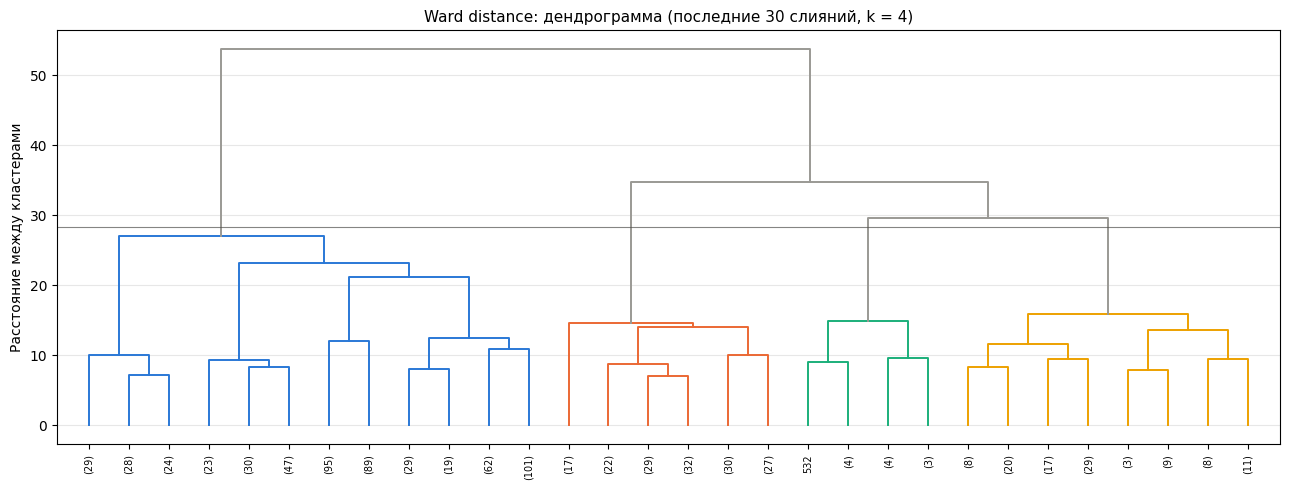

,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,DebtIncomeRatio,cluster
0,41.0,2.0,6.0,19.0,0.124,1.073,6.3,0
1,47.0,1.0,26.0,100.0,4.582,8.218,12.8,1
2,33.0,2.0,10.0,57.0,6.111,5.802,20.9,3
3,29.0,2.0,4.0,19.0,0.681,0.516,6.3,0
4,47.0,1.0,31.0,253.0,9.308,8.908,7.2,2
5,40.0,1.0,23.0,81.0,0.998,7.831,10.9,3
6,38.0,2.0,4.0,56.0,0.442,0.454,1.6,0
7,42.0,3.0,0.0,64.0,0.279,3.945,6.6,0
8,26.0,1.0,5.0,18.0,0.575,2.215,15.5,0
9,47.0,3.0,23.0,115.0,0.653,3.947,4.0,1


In [5]:
def hierarchical(data, linkage, k=4, p=30, plot=True):
    X = standardize(data.to_numpy(float))
    Z = agglomerative(pairwise(X, X), linkage)
    points = data.assign(cluster=cut(Z, k))
    if plot:
        fig, ax = plt.subplots(figsize=(13, 5))
        plot_dendrogram(ax, Z, k, p, f'{LINKAGES[linkage]}: дендрограмма (последние {p} слияний, k = {k})')
        plt.tight_layout()
        fig.savefig(f'dendrogram_{linkage}.png', dpi=150, bbox_inches='tight')
        plt.show()
    return Z, points


Z_ward, points = hierarchical(data, 'ward')
points.head(10)

In [6]:
pd.DataFrame(Z_ward[-10:], columns=['кластер 1', 'кластер 2', 'расстояние', 'размер']).astype({'кластер 1': int, 'кластер 2': int, 'размер': int})

,кластер 1,кластер 2,расстояние,размер
0,1676,1682,14.0175,140
1,1667,1689,14.6046,157
2,1677,1681,14.8782,12
3,1685,1688,15.9194,105
4,1686,1687,21.1954,395
5,1678,1693,23.2294,495
6,1683,1694,27.0990,576
7,1691,1692,29.5610,117
8,1690,1696,34.8194,274
9,1695,1697,53.7344,850


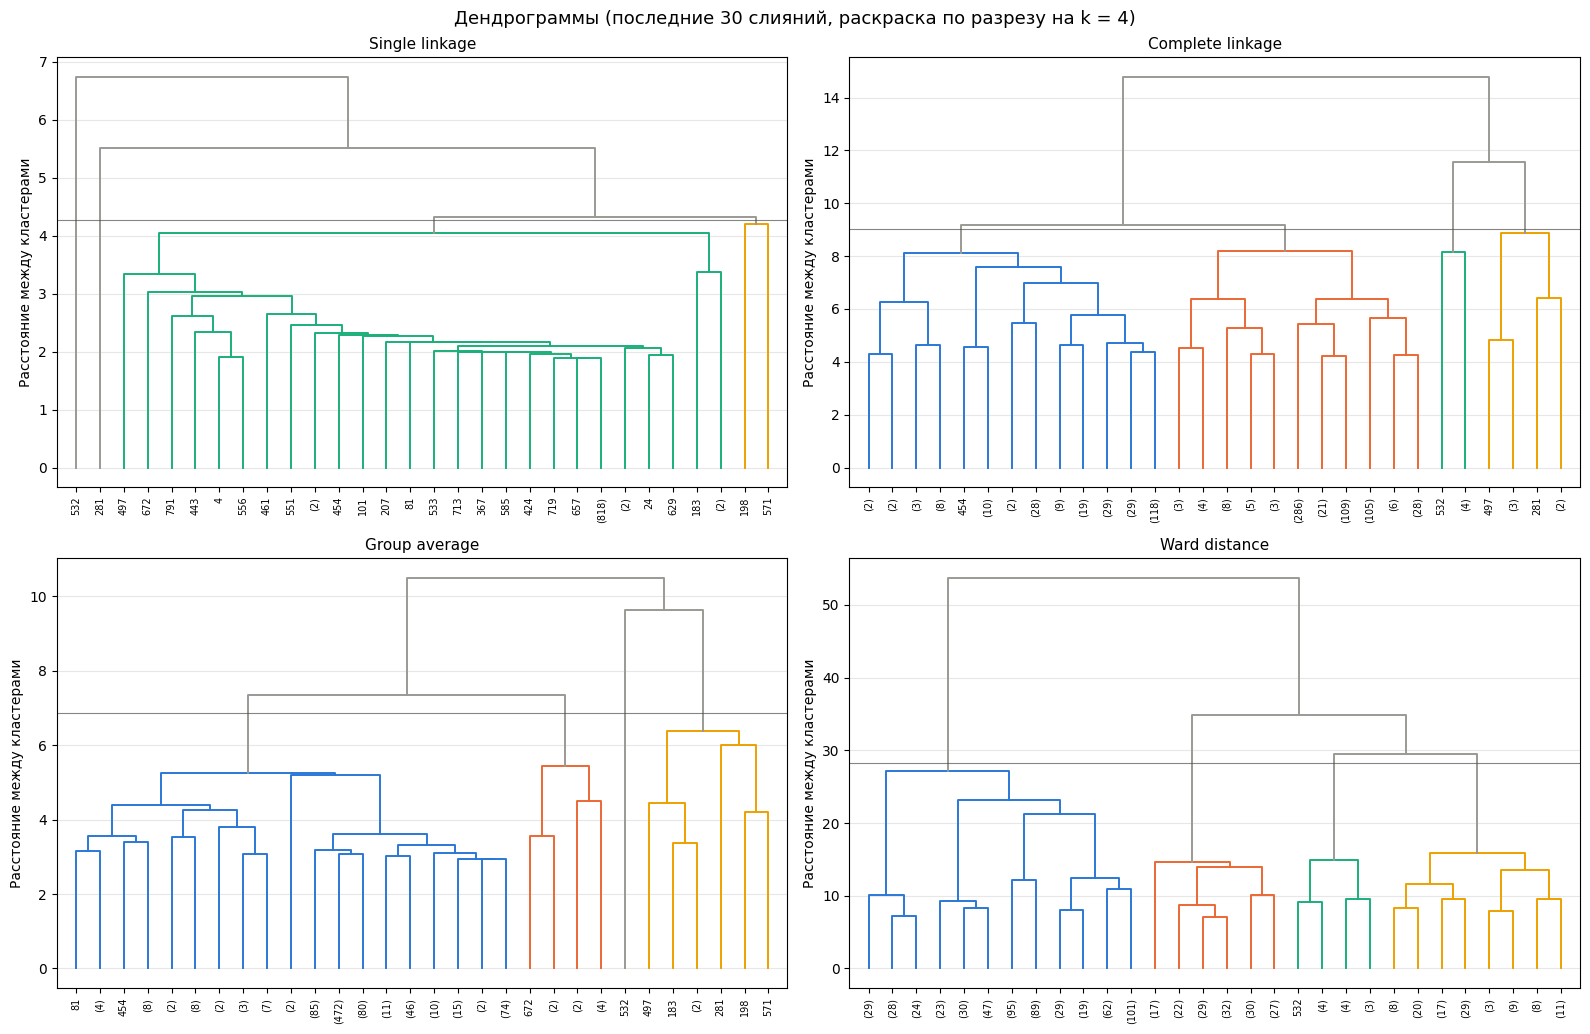

In [7]:
K_SHOW = 4
trees = {m: agglomerative(D, m) for m in LINKAGES}

fig, axes = plt.subplots(2, 2, figsize=(16, 10.5))
for ax, (m, name) in zip(axes.flat, LINKAGES.items()):
    plot_dendrogram(ax, trees[m], K_SHOW, 30, name)
plt.suptitle(f'Дендрограммы (последние 30 слияний, раскраска по разрезу на k = {K_SHOW})', fontsize=13)
plt.tight_layout()
fig.savefig('dendrograms.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
iu = np.triu_indices(len(D), 1)
summary = pd.DataFrame({
    'кофенетическая корреляция': {LINKAGES[m]: np.corrcoef(D[iu], cophenetic(Z)[iu])[0, 1] for m, Z in trees.items()},
    'высота последнего слияния': {LINKAGES[m]: Z[-1, 2] for m, Z in trees.items()},
})
summary

,кофенетическая корреляция,высота последнего слияния
Single linkage,0.8360,6.7402
Complete linkage,0.6596,14.7834
Group average,0.8520,10.4897
Ward distance,0.4962,53.7344


In [9]:
sizes = pd.DataFrame({LINKAGES[m]: np.sort(np.bincount(cut(Z, K_SHOW)))[::-1] for m, Z in trees.items()},
                     index=[f'кластер {i + 1}' for i in range(K_SHOW)])
sizes.T

,кластер 1,кластер 2,кластер 3,кластер 4
Single linkage,846,2,1,1
Complete linkage,578,260,7,5
Group average,833,9,7,1
Ward distance,576,157,105,12


In [10]:
class KMeans:
    NAME = 'k-Means'
    ERROR = 'SSE (сумма квадратов расстояний до центров)'

    def __init__(self, k, n_init=10, max_iter=300, seed=42):
        self.k, self.n_init, self.max_iter = k, n_init, max_iter
        self.rng = np.random.default_rng(seed)

    def _init_centers(self, X):
        centers = [X[self.rng.integers(len(X))]]
        for _ in range(1, self.k):
            d2 = (pairwise(X, np.array(centers)) ** 2).min(1)
            centers.append(X[self.rng.choice(len(X), p=d2 / d2.sum())])
        return np.array(centers)

    def _run(self, X):
        centers = self._init_centers(X)
        labels = None
        for _ in range(self.max_iter):
            new = pairwise(X, centers).argmin(1)
            if labels is not None and np.array_equal(new, labels):
                break
            labels = new
            for j in range(self.k):
                members = X[labels == j]
                centers[j] = members.mean(0) if len(members) else X[pairwise(X, centers).min(1).argmax()]
        error = ((X - centers[labels]) ** 2).sum()
        return centers, labels, error

    def fit(self, X):
        self.centers, self.labels, self.error = min((self._run(X) for _ in range(self.n_init)), key=lambda r: r[2])
        return self


class KMedoids:
    NAME = 'k-Medoids'
    ERROR = 'сумма расстояний до медоидов'

    def __init__(self, k, max_iter=100):
        self.k, self.max_iter = k, max_iter

    def _build(self, D):
        medoids = [D.sum(0).argmin()]
        nearest = D[:, medoids[0]]
        for _ in range(1, self.k):
            cost = np.minimum(nearest[:, None], D).sum(0)
            cost[medoids] = np.inf
            medoids.append(cost.argmin())
            nearest = np.minimum(nearest, D[:, medoids[-1]])
        return np.array(medoids)

    def _swap(self, D, medoids):
        n = len(D)
        for _ in range(self.max_iter):
            dm = D[:, medoids]
            order = np.argsort(dm, axis=1)
            nearest = dm[np.arange(n), order[:, 0]]
            second = dm[np.arange(n), order[:, 1]] if self.k > 1 else np.full(n, np.inf)
            current = nearest.sum()
            best = (current - 1e-9, None, None)
            for i in range(self.k):
                without_i = np.where(order[:, 0] == i, second, nearest)
                cost = np.minimum(without_i[:, None], D).sum(0)
                cost[medoids] = np.inf
                h = cost.argmin()
                if cost[h] < best[0]:
                    best = (cost[h], i, h)
            if best[1] is None:
                break
            medoids[best[1]] = best[2]
        return medoids

    def fit(self, X):
        D = pairwise(X, X)
        self.medoids = self._swap(D, self._build(D))
        self.centers = X[self.medoids]
        self.labels = D[:, self.medoids].argmin(1)
        self.error = D[np.arange(len(X)), self.medoids[self.labels]].sum()
        return self

In [11]:
def adjusted_rand(a, b):
    comb2 = lambda x: (x * (x - 1) / 2).sum()
    table = pd.crosstab(a, b).to_numpy()
    index, rows, cols = comb2(table), comb2(table.sum(1)), comb2(table.sum(0))
    expected = rows * cols / comb2(np.array([len(a)]))
    return (index - expected) / ((rows + cols) / 2 - expected)


def sse(X, labels):
    return sum(((X[labels == c] - X[labels == c].mean(0)) ** 2).sum() for c in np.unique(labels))


def medoid_error(D, labels):
    return sum(D[np.ix_(labels == c, labels == c)].sum(0).min() for c in np.unique(labels))


K_RANGE = range(3, 10)
METHODS = {**LINKAGES, 'kmeans': 'k-Means', 'kmedoids': 'k-Medoids'}

partitions = {}
for k in K_RANGE:
    for m, Z in trees.items():
        partitions[m, k] = cut(Z, k)
    partitions['kmeans', k] = KMeans(k).fit(X).labels
    partitions['kmedoids', k] = KMedoids(k).fit(X).labels

rows = []
for (m, k), labels in partitions.items():
    rows.append({'method': METHODS[m], 'k': k, 'SSE': sse(X, labels), 'medoid_error': medoid_error(D, labels),
                 'ARI_kmeans': adjusted_rand(partitions['kmeans', k], labels),
                 'ARI_kmedoids': adjusted_rand(partitions['kmedoids', k], labels)})
results = pd.DataFrame(rows)
results.pivot(index='k', columns='method', values='SSE')[list(METHODS.values())]

method,Single linkage,Complete linkage,Group average,Ward distance,k-Means,k-Medoids
k,,,,,,
3,5624.3605,4980.3952,5190.9545,3900.1145,3702.4198,3861.0168
4,5442.2520,4038.4318,4827.9917,3463.1876,3232.7065,3353.0477
5,5433.4143,3992.2527,4781.8126,3096.0095,2869.0195,3038.5668
6,5178.0242,3649.1013,4760.5808,2826.2079,2603.2543,2883.0009
7,5170.7838,3607.8187,4717.0997,2601.5861,2400.1935,2782.7866
8,5094.5832,3445.5915,4156.4532,2474.8725,2273.6320,2621.7275
9,5046.3930,3269.5414,4112.1772,2364.1924,2167.6040,2365.0095


In [12]:
results.pivot(index='k', columns='method', values='medoid_error')[list(METHODS.values())]

method,Single linkage,Complete linkage,Group average,Ward distance,k-Means,k-Medoids
k,,,,,,
3,1982.5434,1933.3020,1951.1723,1680.5487,1630.1385,1615.5180
4,1967.2456,1747.2329,1918.6247,1643.8801,1575.9595,1492.6640
5,1963.0414,1740.5557,1911.9475,1551.2048,1469.2010,1407.3627
6,1939.4641,1697.6620,1906.3646,1480.3297,1417.2106,1351.4146
7,1936.0943,1690.2997,1895.2972,1406.9133,1369.4475,1307.8534
8,1927.2825,1664.4312,1817.1614,1386.0121,1337.5454,1273.4782
9,1920.3960,1633.0901,1809.6990,1367.5371,1301.0685,1234.5071


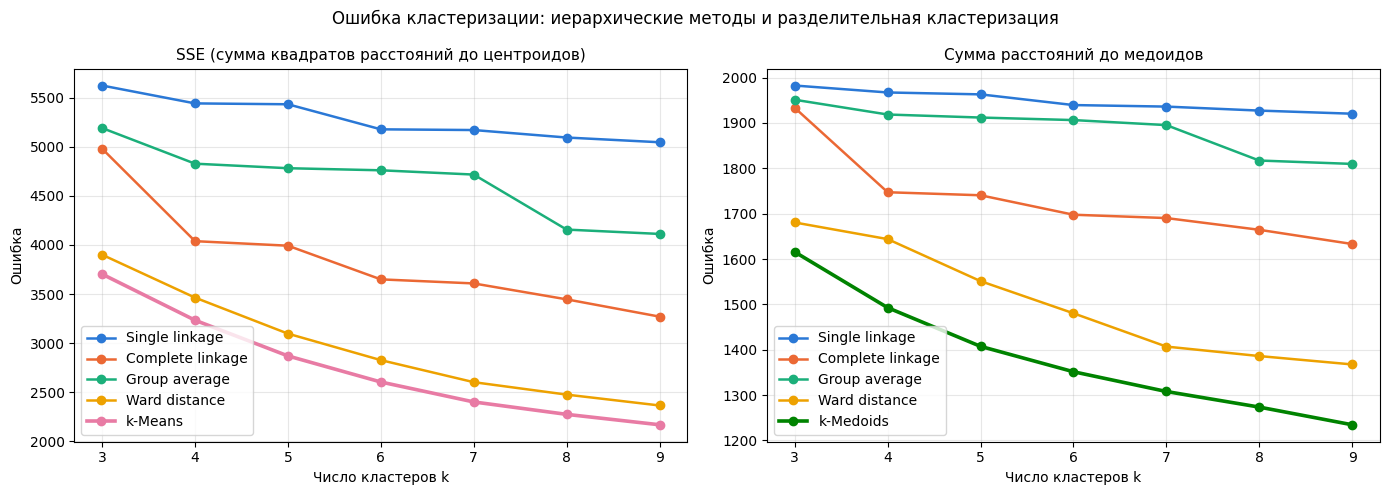

In [13]:
METHOD_COLORS = dict(zip(METHODS.values(), COLORS))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (col, title, ref) in zip(axes, [('SSE', 'SSE (сумма квадратов расстояний до центроидов)', 'k-Means'),
                                        ('medoid_error', 'Сумма расстояний до медоидов', 'k-Medoids')]):
    for name in list(LINKAGES.values()) + [ref]:
        grp = results[results['method'] == name]
        ax.plot(grp['k'], grp[col], marker='o', lw=2.6 if name == ref else 1.8, color=METHOD_COLORS[name], label=name)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Число кластеров k')
    ax.set_ylabel('Ошибка')
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
    ax.legend()
plt.suptitle('Ошибка кластеризации: иерархические методы и разделительная кластеризация')
plt.tight_layout()
fig.savefig('error_vs_k.png', dpi=150, bbox_inches='tight')
plt.show()

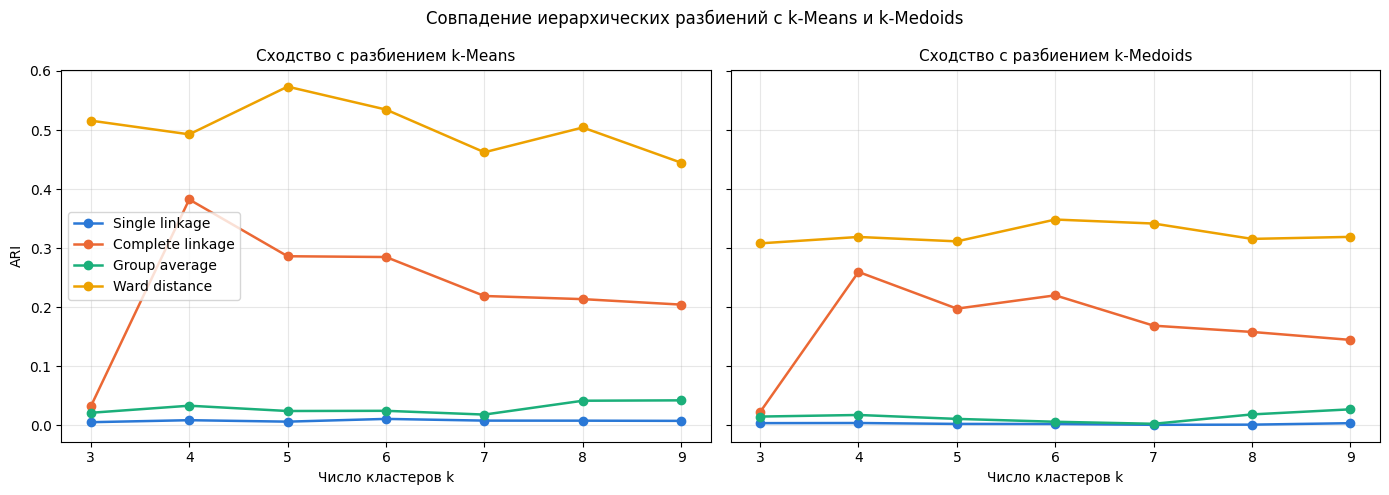

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (col, ref) in zip(axes, [('ARI_kmeans', 'k-Means'), ('ARI_kmedoids', 'k-Medoids')]):
    for name in LINKAGES.values():
        grp = results[results['method'] == name]
        ax.plot(grp['k'], grp[col], marker='o', lw=1.8, color=METHOD_COLORS[name], label=name)
    ax.set_title(f'Сходство с разбиением {ref}', fontsize=11)
    ax.set_xlabel('Число кластеров k')
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
axes[0].set_ylabel('ARI')
axes[0].legend()
plt.suptitle('Совпадение иерархических разбиений с k-Means и k-Medoids')
plt.tight_layout()
fig.savefig('ari_vs_k.png', dpi=150, bbox_inches='tight')
plt.show()

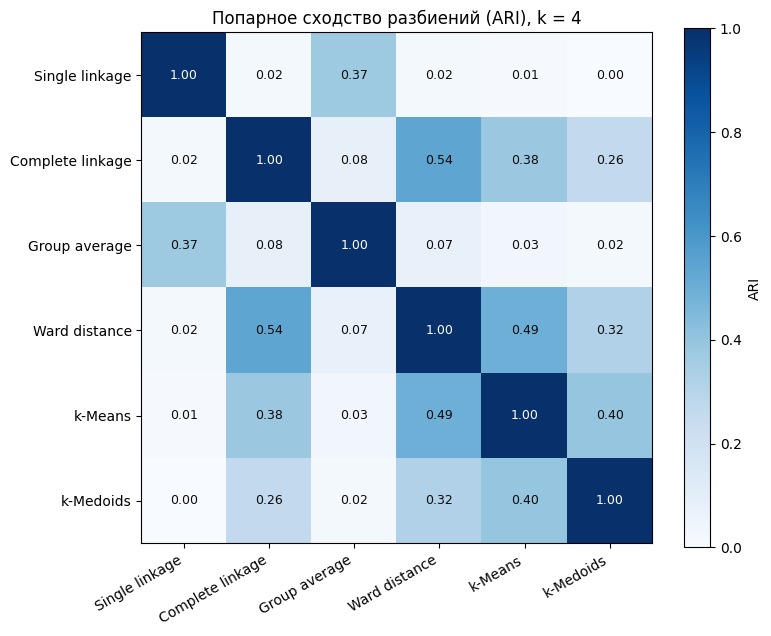

In [15]:
names = list(METHODS)
ari = np.array([[adjusted_rand(partitions[a, K_SHOW], partitions[b, K_SHOW]) for b in names] for a in names])

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(ari, cmap='Blues', vmin=0, vmax=1)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{ari[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if ari[i, j] > 0.6 else '#0b0b0b')
labels = list(METHODS.values())
ax.set_xticks(range(len(names)))
ax.set_xticklabels(labels, rotation=30, ha='right')
ax.set_yticks(range(len(names)))
ax.set_yticklabels(labels)
fig.colorbar(im, ax=ax, label='ARI')
ax.set_title(f'Попарное сходство разбиений (ARI), k = {K_SHOW}')
plt.tight_layout()
fig.savefig('ari_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

Доля объяснённой дисперсии PC1, PC2: [0.441 0.21 ]


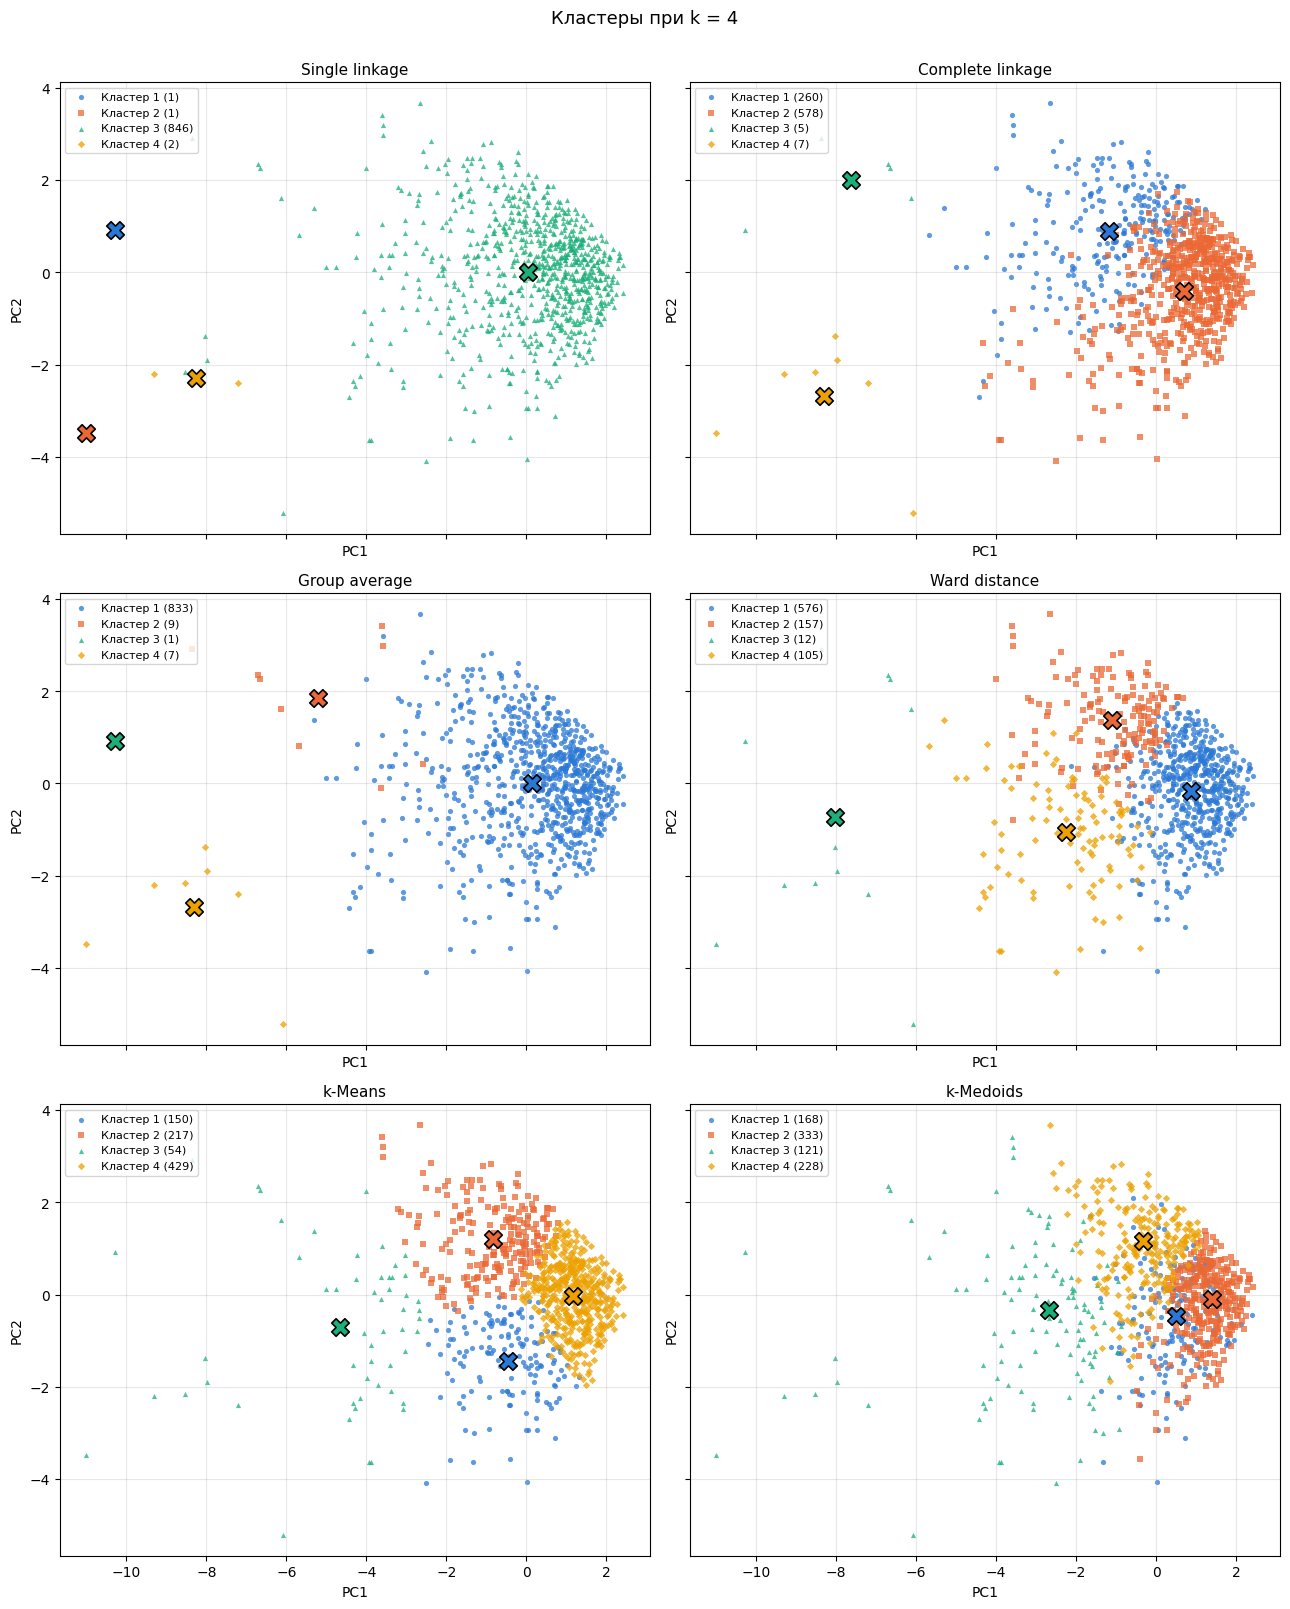

In [16]:
_, s, Vt = np.linalg.svd(X, full_matrices=False)
XY = X @ Vt[:2].T
print('Доля объяснённой дисперсии PC1, PC2:', np.round(s[:2] ** 2 / (s ** 2).sum(), 3))

fig, axes = plt.subplots(3, 2, figsize=(13, 16), sharex=True, sharey=True)
for ax, m in zip(axes.flat, names):
    labels = partitions[m, K_SHOW]
    for j in range(K_SHOW):
        mask = labels == j
        ax.scatter(*XY[mask].T, s=14, color=COLORS[j], marker=MARKERS[j], alpha=0.75, linewidths=0,
                   label=f'Кластер {j + 1} ({mask.sum()})')
        if m == 'kmedoids':
            idx = np.flatnonzero(mask)
            center = XY[idx[D[np.ix_(idx, idx)].sum(0).argmin()]]
        else:
            center = XY[mask].mean(0)
        ax.scatter(*center, s=160, color=COLORS[j], marker='X', edgecolors='black', linewidths=1.2, zorder=3)
    ax.set_title(METHODS[m], fontsize=11)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='upper left')
plt.suptitle(f'Кластеры при k = {K_SHOW}', y=1.003, fontsize=13)
plt.tight_layout()
fig.savefig('scatter_methods.png', dpi=150, bbox_inches='tight')
plt.show()